# Rod Batch Analysis
Measures the **oxic layer depth** (mm) for each cropped rod image.

**Pipeline per rod:**
1. Load crop → take centre 70% of width
2. Build normalised row-intensity profile
3. Find **surface marker** — the black reference mark on the rod
4. Find **inflection point** — where intensity transitions into the anoxic zone
5. Compute depth in mm, plot diagnostics, export CSV

In [253]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.signal import savgol_filter
import os, csv

## Parameters

In [254]:
# ── Input / Output ────────────────────────────────────────────────────────────
CROPS_DIR    = "rod_crops_foer"    # folder containing cropped rod images
ANALYSIS_DIR = "analysis"     # folder where plots and CSV are saved

# ── Physical calibration ──────────────────────────────────────────────────────
ROD_LENGTH   = 305            # total rod length in mm

# ── Width crop (removes rod edges / bright reflections) ──────────────────────
WIDTH_FRAC   = 1      # keep centre 80% of each crop's width

# ── Surface marker search ─────────────────────────────────────────────────────
SURF_START   = 0.40           # start searching at this fraction of image height
SURF_END     = 0.90           # stop  searching at this fraction of image height
SURF_WIN     = 0.015          # half-window for local-dip scoring (fraction of height)

# ── Inflection point search ───────────────────────────────────────────────────
INF_OFFSET   = 0.05           # start this far below surface marker (fraction of height)
INF_END      = 0.05           # stop this far from the bottom (fraction of height)
SGF_WINDOW   = 151            # Savitzky-Golay smoothing window (must be odd)
SGF_TRIM     = 50             # ignore this many points at each end of the derivative

MIN_INTENSITY_DROP = 0.05   # smoothed intensity must drop by at least this amount


## Collect images

In [255]:
VALID_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
image_files = sorted([
    f for f in os.listdir(CROPS_DIR)
    if os.path.splitext(f)[1].lower() in VALID_EXT
])

assert image_files, f"No images found in '{CROPS_DIR}'"
os.makedirs(ANALYSIS_DIR, exist_ok=True)

print(f"Found {len(image_files)} image(s) in '{CROPS_DIR}':")
for f in image_files:
    print(f"  {f}")

Found 9 image(s) in 'rod_crops_foer':
  ekseperiment_foer_omroering_rod_02.png
  ekseperiment_foer_omroering_rod_03.png
  ekseperiment_foer_omroering_rod_04.png
  ekseperiment_foer_omroering_rod_05.png
  ekseperiment_foer_omroering_rod_06.png
  ekseperiment_foer_omroering_rod_07.png
  ekseperiment_foer_omroering_rod_08.png
  ekseperiment_foer_omroering_rod_09.png
  ekseperiment_foer_omroering_rod_10.png


## Helper functions

In [256]:
def find_surface(row_n, img_h):
    """Find the black reference mark — the sharpest local intensity dip."""
    r0  = int(img_h * SURF_START)
    r1  = int(img_h * SURF_END)
    win = max(5, int(img_h * SURF_WIN))
    best_score, surface = 0.0, r0
    for i in range(r0 + win, r1 - win):
        score = ((row_n[i - win] + row_n[i + win]) / 2.0) - row_n[i]
        if score > best_score:
            best_score, surface = score, i
    return surface

def find_inflection(row_n, img_h, surface):
    """Find the negative-to-positive zero crossing of the 2nd derivative.
    Enforces a strict minimum intensity drop to guarantee a true transition
    and correctly output NaN for fully stained or fully unstained rods."""
    
    r_start = surface + int(img_h * INF_OFFSET)
    r_end   = img_h   - int(img_h * INF_END)
    
    assert r_start < r_end, "Search range empty. Lower INF_OFFSET."
    
    f  = row_n[r_start:r_end]
    wl = min(SGF_WINDOW, len(f) if len(f) % 2 == 1 else len(f) - 1)
    
    f_smooth = savgol_filter(f, window_length=wl, polyorder=3, mode="interp")
    f1       = savgol_filter(f, window_length=wl, polyorder=3, deriv=1, mode="interp")
    f2       = savgol_filter(f, window_length=wl, polyorder=3, deriv=2, mode="interp")
    
    trim = min(SGF_TRIM, len(f) // 5)
    f2t = f2.copy()
    f2t[:trim]  = 0
    f2t[-trim:] = 0
    
    # 1. Find all negative-to-positive zero crossings of 2nd derivative
    zero_crossings = np.where((f2t[:-1] < 0) & (f2t[1:] >= 0))[0]
    
    if len(zero_crossings) == 0:
        return None, f_smooth, f1, f2, np.arange(r_start, r_end)
        
    # 2. INTENSITY DROP GUARDRAIL
    valid_idx = None
    for idx in zero_crossings:
        
        # Find the absolute brightest point BEFORE this crossing
        # This prevents issues if f_smooth[0] starts in a shadow
        max_intensity_before = np.max(f_smooth[:idx+1]) 
        
        # Calculate the drop from that peak down to the crossing
        intensity_drop = max_intensity_before - f_smooth[idx]
        
        # ONLY accept it if it drops by at least the threshold AND the slope is downward
        if intensity_drop >= MIN_INTENSITY_DROP and f1[idx] < 0:
            valid_idx = idx
            break  
            
    if valid_idx is None:
        return None, f_smooth, f1, f2, np.arange(r_start, r_end)
    
    return r_start + valid_idx, f_smooth, f1, f2, np.arange(r_start, r_end)

## Process all rods


Processing: ekseperiment_foer_omroering_rod_02.png
  ⚠ No negative-to-positive zero crossing found — depth set to NaN
  Surface:    row 1028  (73.3% of height)
  Inflection: row 1028  (73.3% of height)
  Oxic depth: nan


C:\Users\mtloo\AppData\Local\Temp\ipykernel_45972\876569595.py:108: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


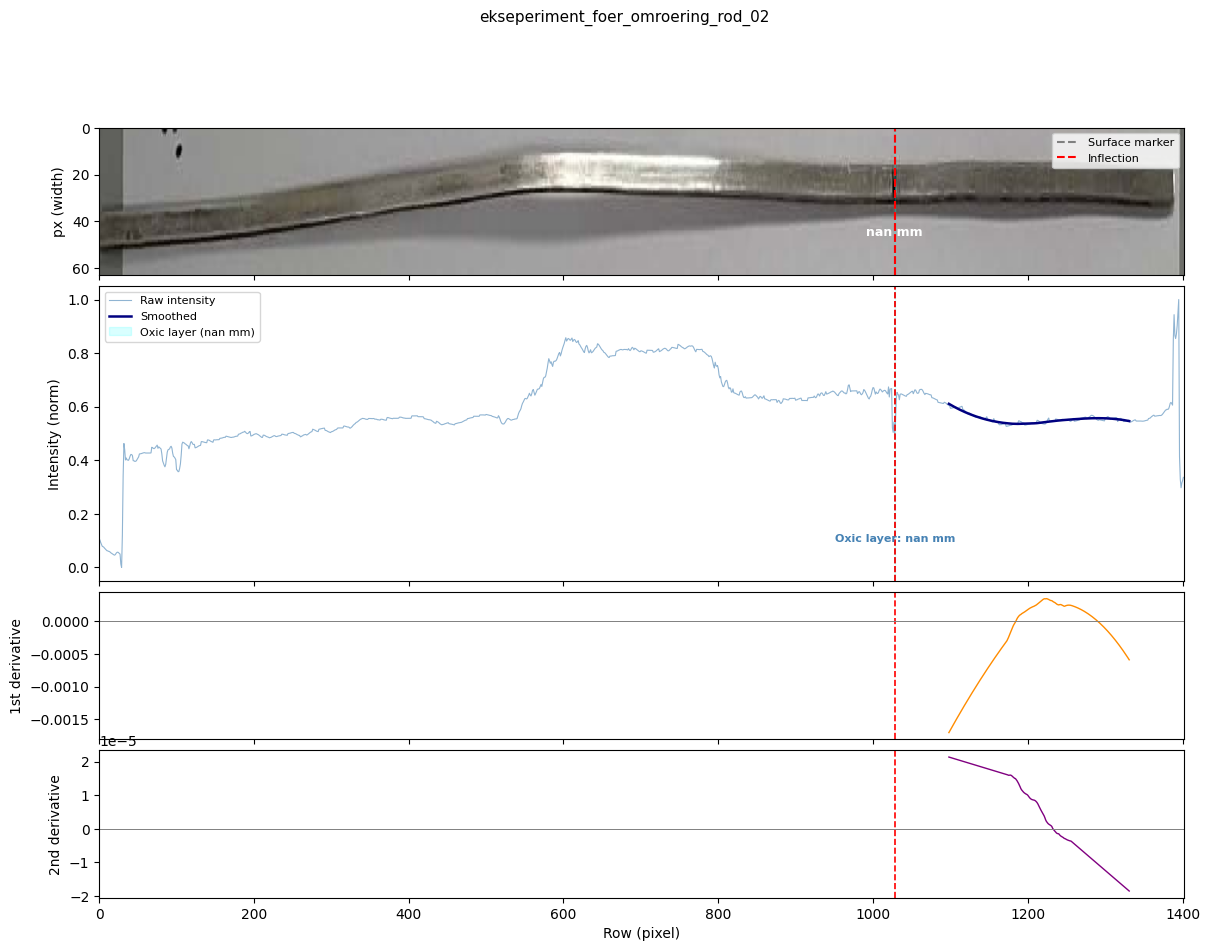

  Plot saved → analysis\ekseperiment_foer_omroering_rod_02_analysis.png

Processing: ekseperiment_foer_omroering_rod_03.png
  Surface:    row 963  (68.7% of height)
  Inflection: row 1171  (83.5% of height)
  Oxic depth: 45.24964336661912


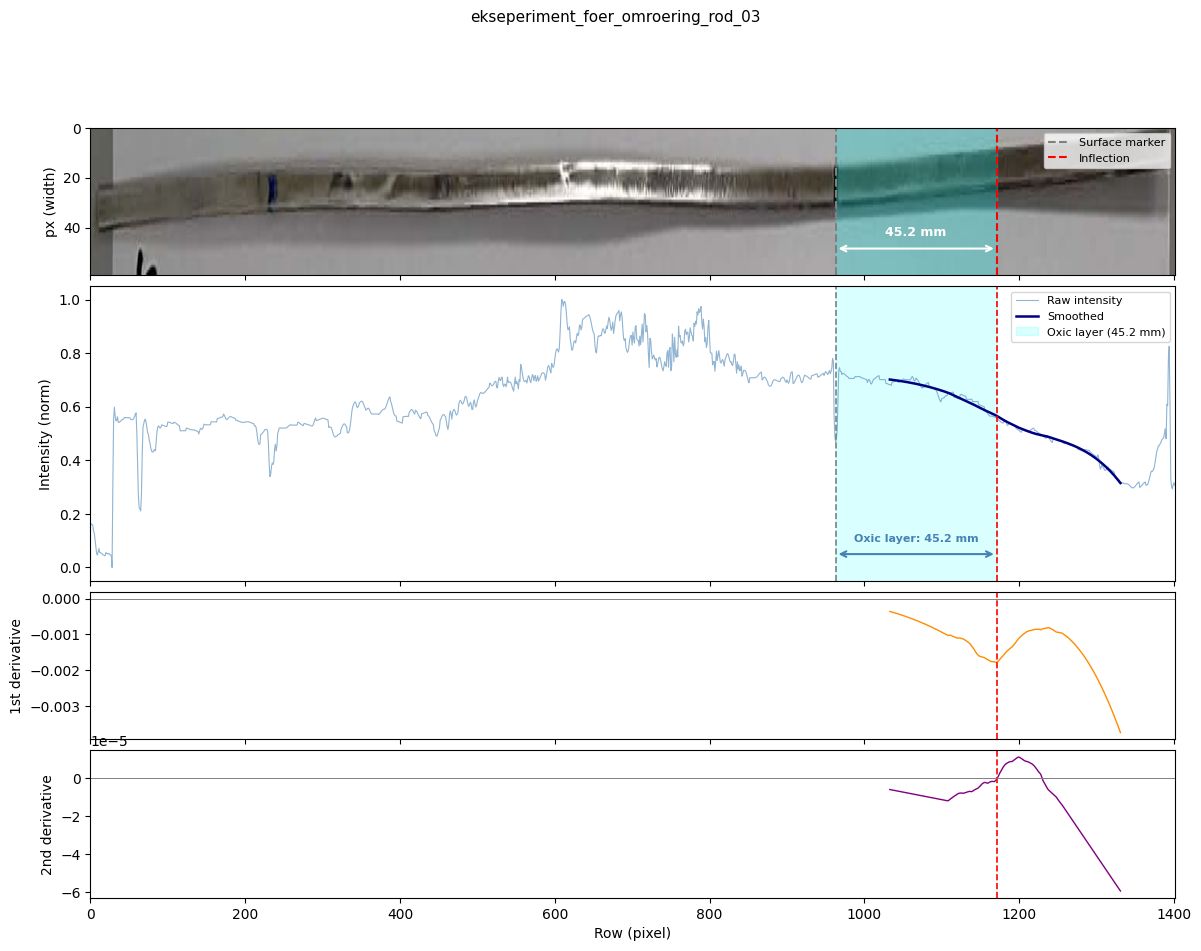

  Plot saved → analysis\ekseperiment_foer_omroering_rod_03_analysis.png

Processing: ekseperiment_foer_omroering_rod_04.png
  Surface:    row 1000  (71.3% of height)
  Inflection: row 1257  (89.7% of height)
  Oxic depth: 55.90941512125535


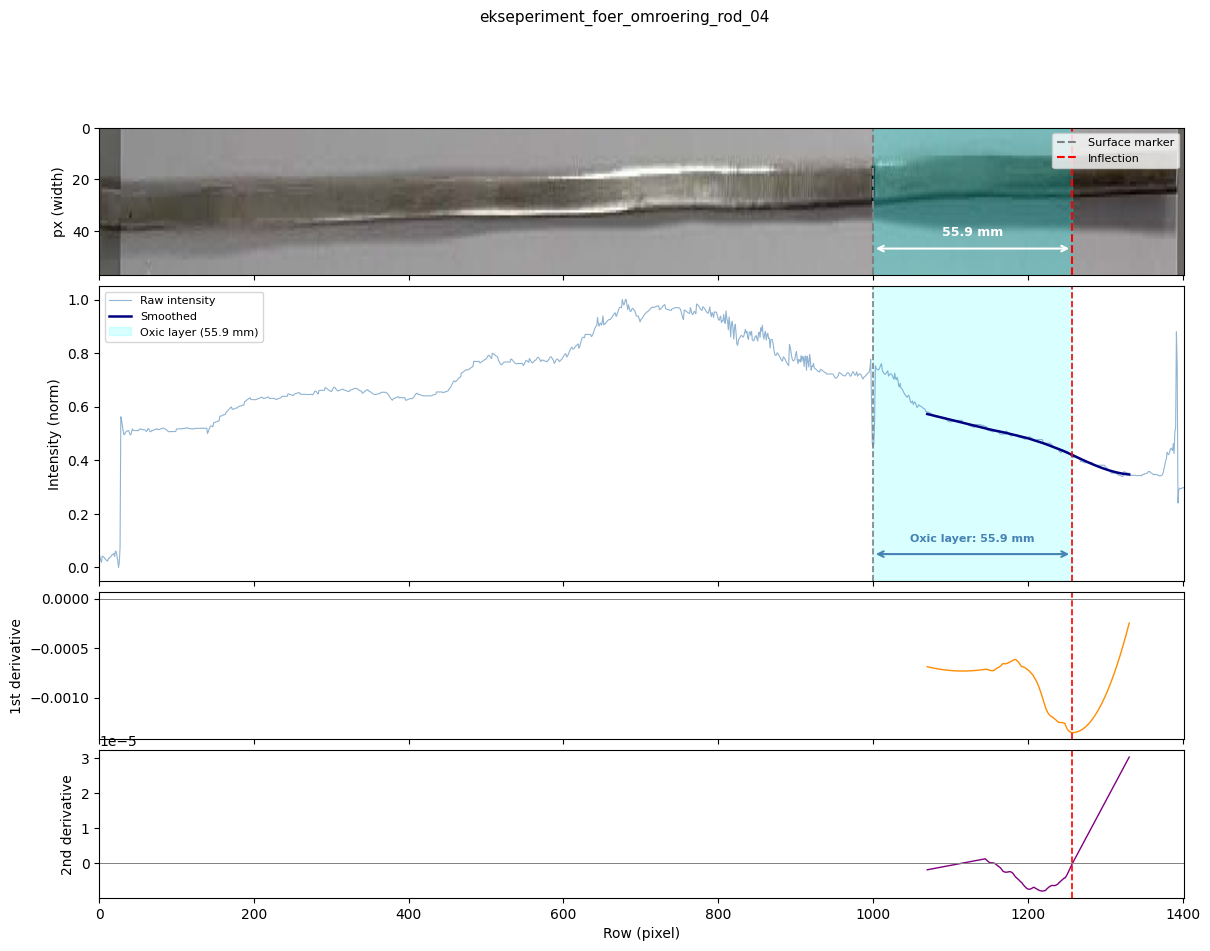

  Plot saved → analysis\ekseperiment_foer_omroering_rod_04_analysis.png

Processing: ekseperiment_foer_omroering_rod_05.png
  ⚠ No negative-to-positive zero crossing found — depth set to NaN
  Surface:    row 986  (70.3% of height)
  Inflection: row 986  (70.3% of height)
  Oxic depth: nan


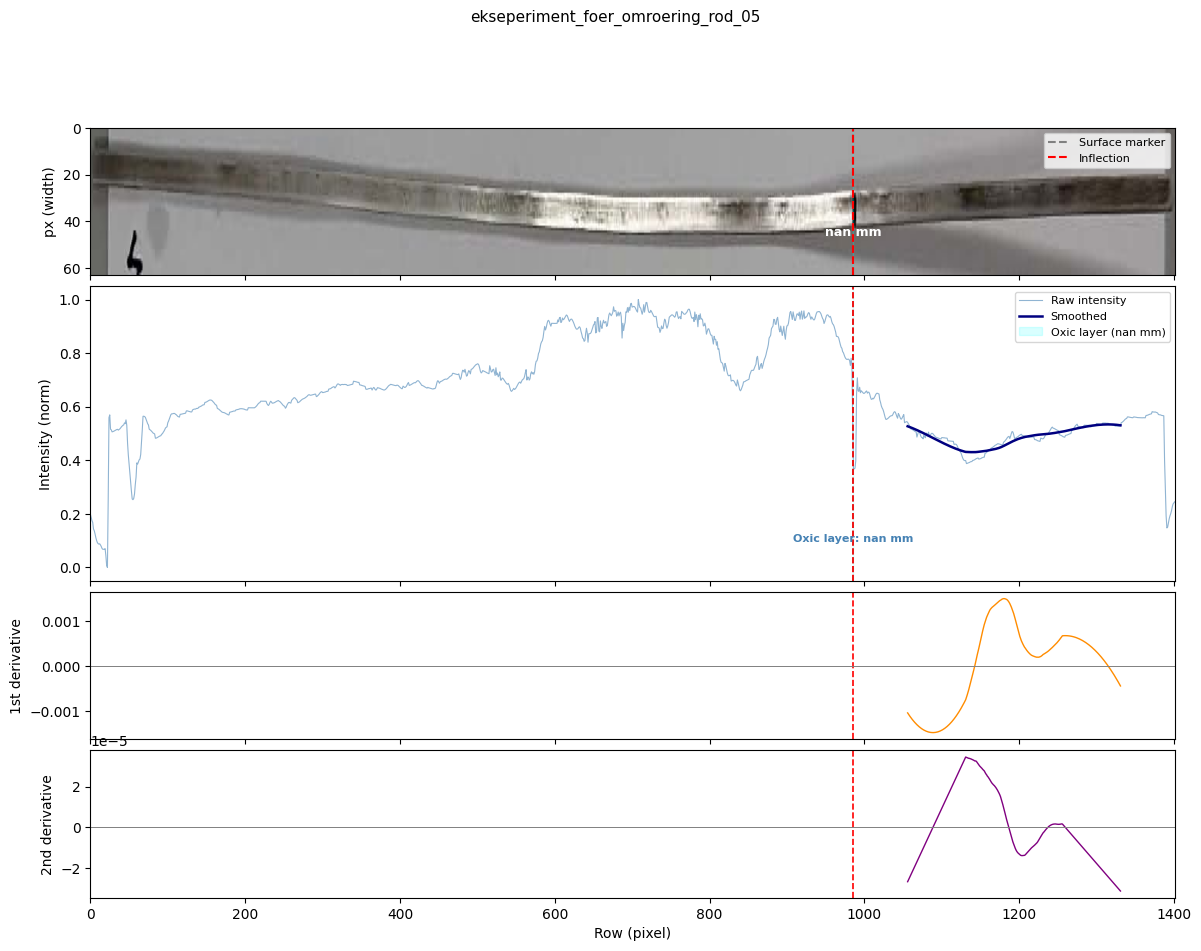

  Plot saved → analysis\ekseperiment_foer_omroering_rod_05_analysis.png

Processing: ekseperiment_foer_omroering_rod_06.png
  ⚠ No negative-to-positive zero crossing found — depth set to NaN
  Surface:    row 956  (68.2% of height)
  Inflection: row 956  (68.2% of height)
  Oxic depth: nan


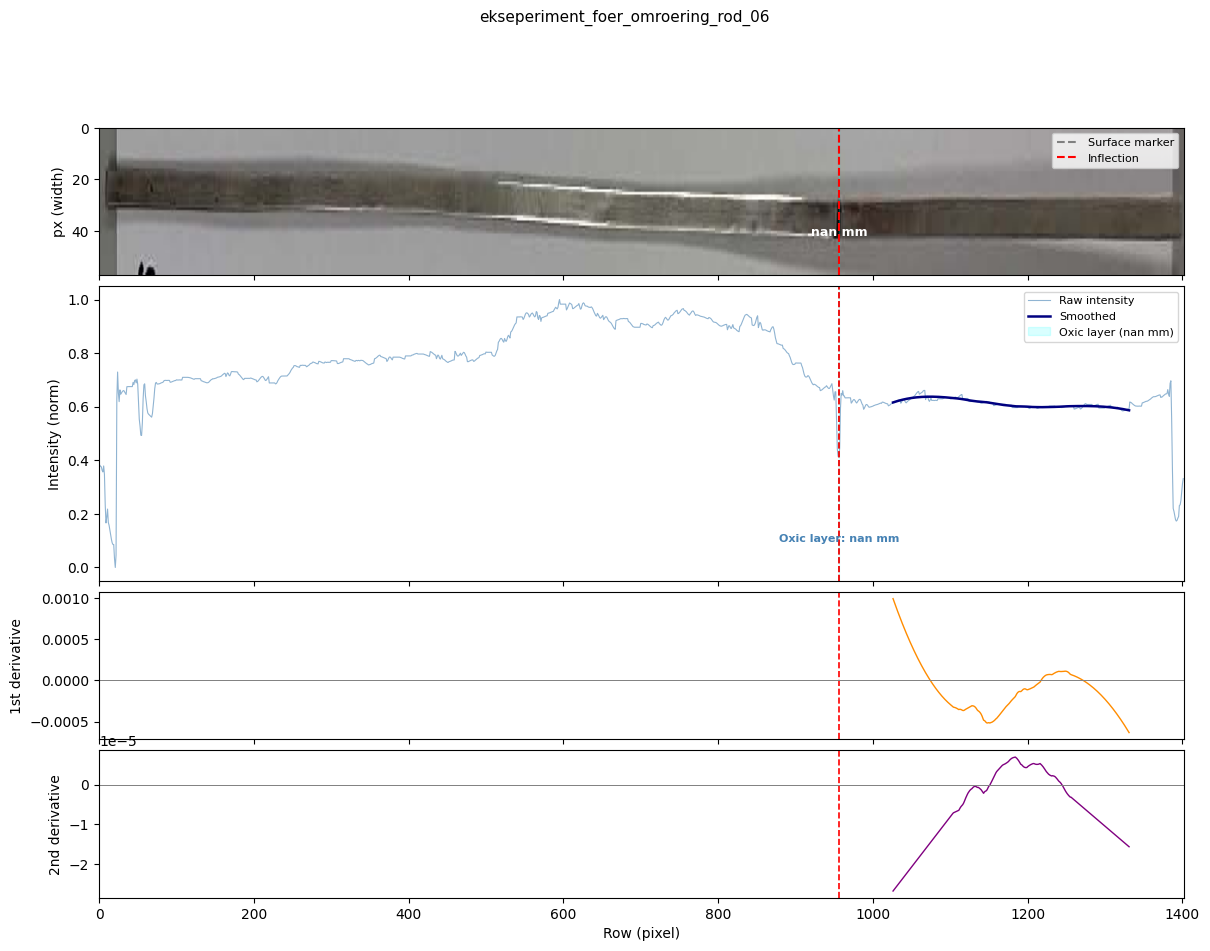

  Plot saved → analysis\ekseperiment_foer_omroering_rod_06_analysis.png

Processing: ekseperiment_foer_omroering_rod_07.png
  Surface:    row 946  (67.5% of height)
  Inflection: row 1098  (78.3% of height)
  Oxic depth: 33.067047075606276


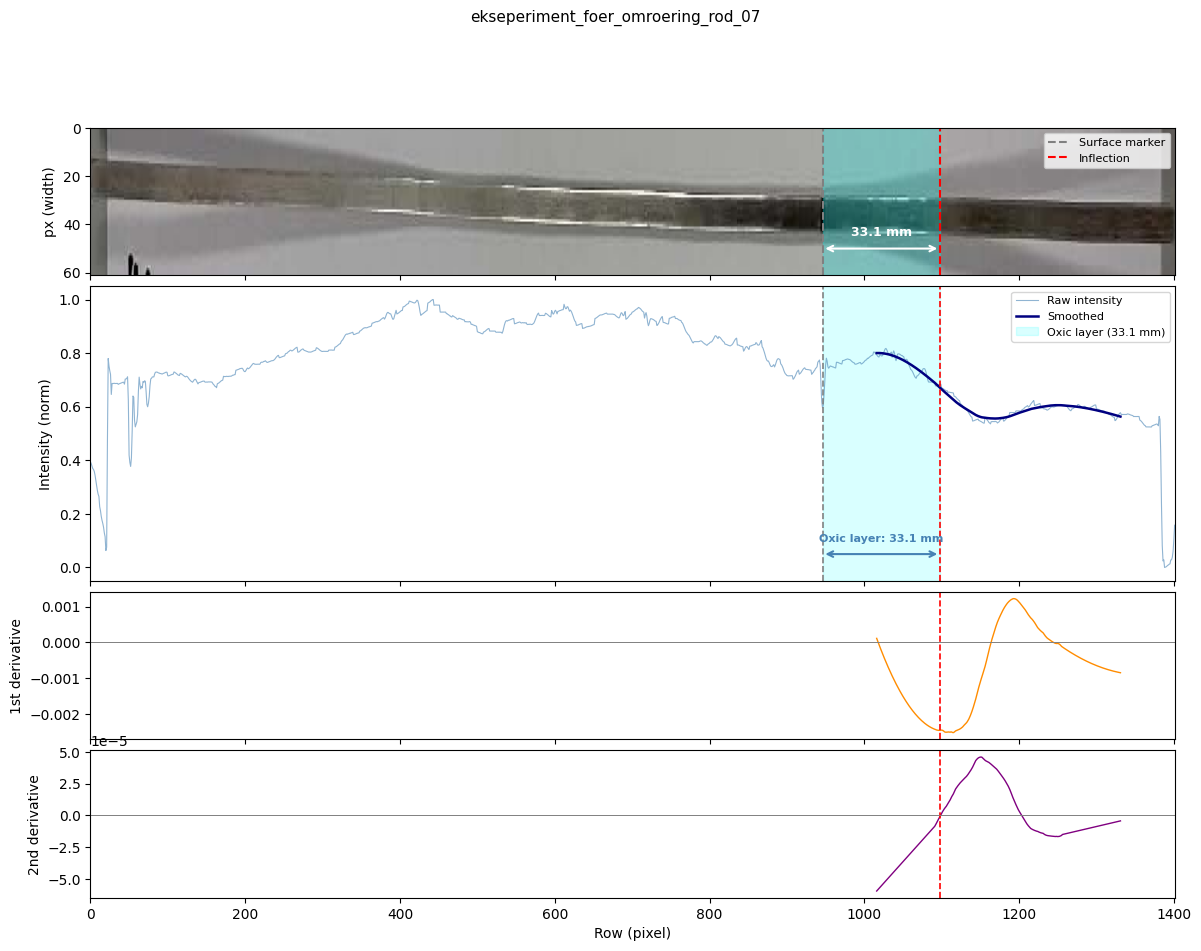

  Plot saved → analysis\ekseperiment_foer_omroering_rod_07_analysis.png

Processing: ekseperiment_foer_omroering_rod_08.png
  Surface:    row 1025  (73.1% of height)
  Inflection: row 1235  (88.1% of height)
  Oxic depth: 45.68473609129815


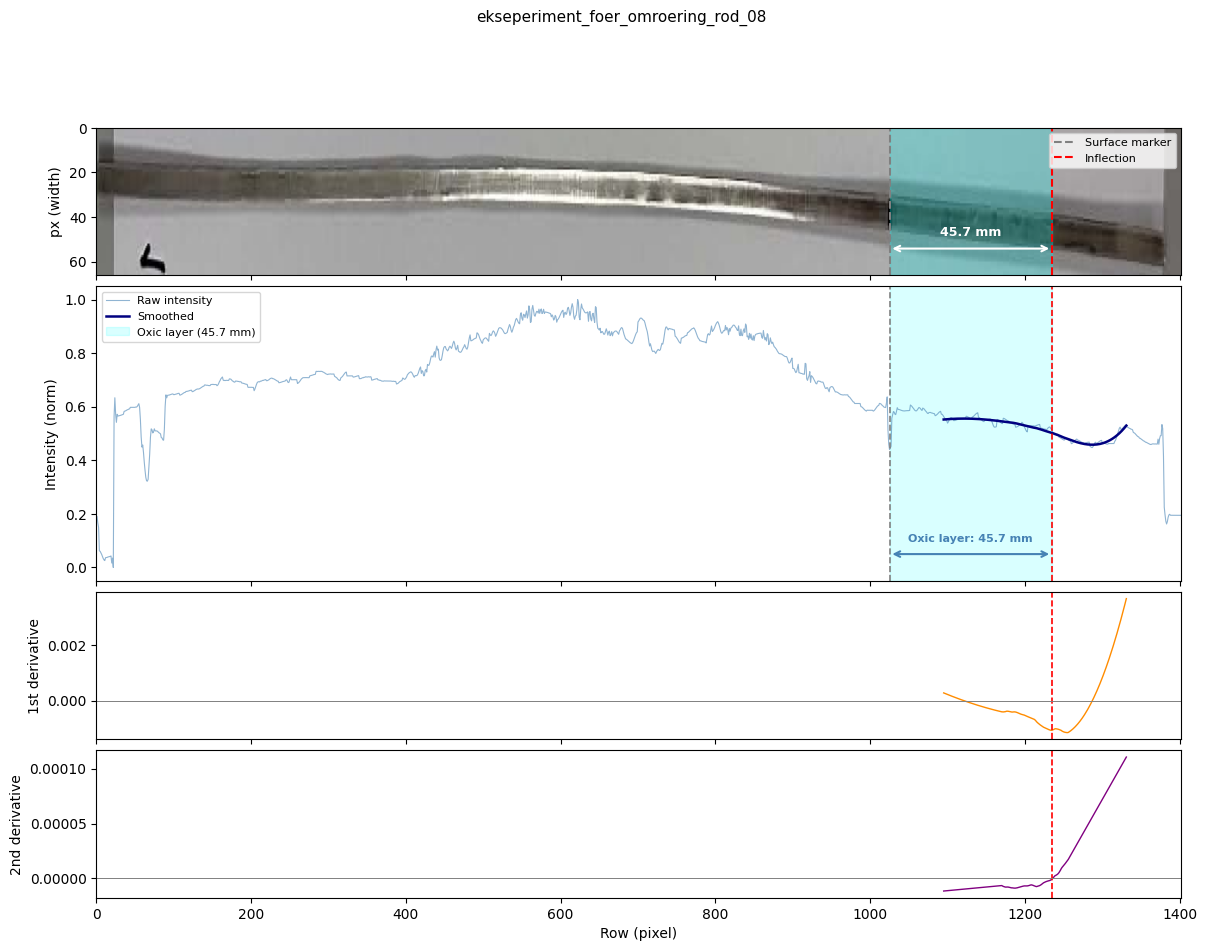

  Plot saved → analysis\ekseperiment_foer_omroering_rod_08_analysis.png

Processing: ekseperiment_foer_omroering_rod_09.png
  ⚠ No negative-to-positive zero crossing found — depth set to NaN
  ⚠ Smoothed intensity rises after inf_start — not a valid transition, depth set to NaN
  Surface:    row 1020  (72.8% of height)
  Inflection: row 1020  (72.8% of height)
  Oxic depth: nan


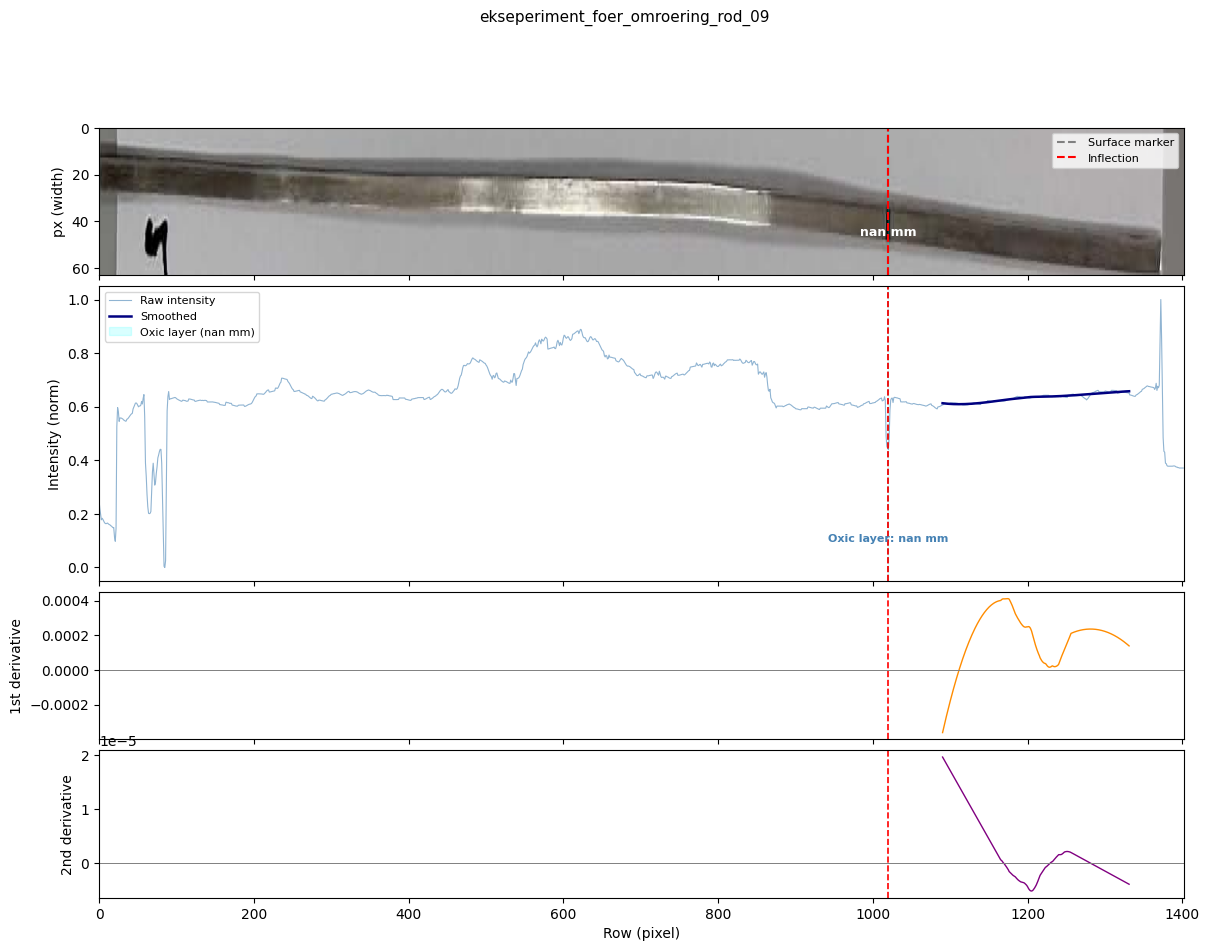

  Plot saved → analysis\ekseperiment_foer_omroering_rod_09_analysis.png

Processing: ekseperiment_foer_omroering_rod_10.png
  Surface:    row 1002  (71.5% of height)
  Inflection: row 1211  (86.4% of height)
  Oxic depth: 45.46718972895863


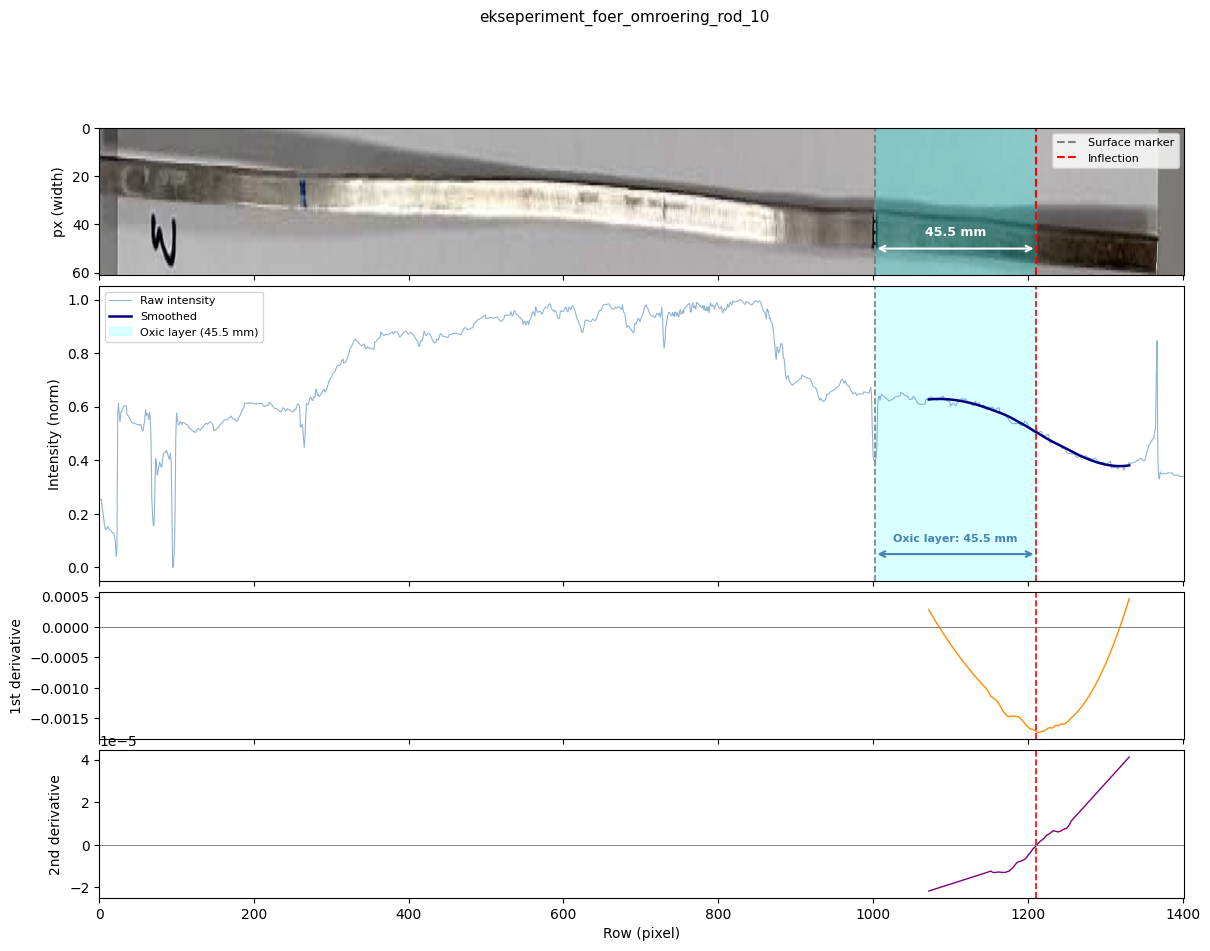

  Plot saved → analysis\ekseperiment_foer_omroering_rod_10_analysis.png


In [257]:
results = []

for filename in image_files:
    path = os.path.join(CROPS_DIR, filename)
    stem = os.path.splitext(filename)[0]
    print(f"\nProcessing: {filename}")

    # ── Load & centre-crop width ───────────────────────────────────────────────
    img_bgr = cv2.imread(path)
    if img_bgr is None:
        print("  Could not read — skipping.")
        continue

    h, w = img_bgr.shape[:2]
    new_w  = int(w * WIDTH_FRAC)
    x0     = (w - new_w) // 2
    img    = img_bgr[:, x0 : x0 + new_w]
    img_h  = img.shape[0]
    img_rgb   = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_horiz = img_rgb.transpose(1, 0, 2)   # rotate for horizontal display

    # ── Row intensity profile ──────────────────────────────────────────────────
    row_sums = img.sum(axis=(1, 2)).astype(float)
    row_n    = (row_sums - row_sums.min()) / (row_sums.max() - row_sums.min())
    rows_all = np.arange(img_h)

    # ── Detect surface marker & inflection ────────────────────────────────────
    surface                          = find_surface(row_n, img_h)
    inflection, f_smooth, f1, f2, r  = find_inflection(row_n, img_h, surface)

    if inflection is None:
        depth_mm   = np.nan
        inflection = surface   # placeholder for plotting only
        print(f"  ⚠ No negative-to-positive zero crossing found — depth set to NaN")
    else:
        depth_mm = ((inflection - surface) / img_h) * ROD_LENGTH
    
    # Check: smoothed intensity must decrease after inflection search start
    check_region = f_smooth[:int(img_h * 0.10)]   # first 10% of smoothed search region
    if len(check_region) > 5:
        post_slope = np.polyfit(np.arange(len(check_region)),
                                check_region, 1)[0]
        if post_slope > 0:
            depth_mm = np.nan
            print(f"  ⚠ Smoothed intensity rises after inf_start — not a valid transition, depth set to NaN")

    results.append({"rod": stem, "surface_row": surface,
                    "inflection_row": inflection,
                    "depth_mm": round(depth_mm, 2) if not np.isnan(depth_mm) else np.nan})
    print(f"  Surface:    row {surface}  ({surface/img_h*100:.1f}% of height)")
    print(f"  Inflection: row {inflection}  ({inflection/img_h*100:.1f}% of height)")
    print(f"  Oxic depth: {depth_mm}")

    # ── Figure ────────────────────────────────────────────────────────────────
    fig = plt.figure(figsize=(14, 10))
    fig.suptitle(stem, fontsize=11, y=0.998)
    gs  = gridspec.GridSpec(4, 1, height_ratios=[1.5, 3, 1.5, 1.5], hspace=0.06)

    # Panel 0 — rod image (displayed horizontally)
    ax_img = fig.add_subplot(gs[0])
    ax_img.imshow(img_horiz, extent=[0, img_h, img_rgb.shape[1], 0], aspect="auto")
    ax_img.axvspan(surface, inflection, color="cyan", alpha=0.25)
    ax_img.axvline(surface,    color="gray",  ls="--", lw=1.5, label="Surface marker")
    ax_img.axvline(inflection, color="red",   ls="--", lw=1.5, label=f"Inflection")
    mid_y = img_rgb.shape[1] * 0.82
    ax_img.annotate("", xy=(inflection, mid_y), xytext=(surface, mid_y),
                    arrowprops=dict(arrowstyle="<->", color="white", lw=1.5))
    ax_img.text((surface + inflection) / 2, mid_y - img_rgb.shape[1] * 0.07,
                f"{depth_mm:.1f} mm", color="white", fontsize=9,
                ha="center", va="bottom", fontweight="bold")
    ax_img.set_ylabel("px (width)")
    ax_img.tick_params(labelbottom=False)
    ax_img.legend(loc="upper right", fontsize=8)

    # Panel 1 — intensity + smoothed curve
    ax0 = fig.add_subplot(gs[1], sharex=ax_img)
    ax0.plot(rows_all, row_n,   lw=0.8, color="steelblue", alpha=0.6, label="Raw intensity")
    ax0.plot(r,        f_smooth, lw=1.8, color="navy",               label="Smoothed")
    ax0.axvspan(surface, inflection, color="cyan", alpha=0.15,
                label=f"Oxic layer ({depth_mm:.1f} mm)")
    ax0.axvline(surface,    color="gray", ls="--", lw=1.2)
    ax0.axvline(inflection, color="red",  ls="--", lw=1.2)
    ax0.annotate("", xy=(inflection, 0.05), xytext=(surface, 0.05),
                 arrowprops=dict(arrowstyle="<->", color="steelblue", lw=1.5))
    ax0.text((surface + inflection) / 2, 0.09,
             f"Oxic layer: {depth_mm:.1f} mm", color="steelblue",
             fontsize=8, ha="center", va="bottom", fontweight="bold")
    ax0.set_ylabel("Intensity (norm)")
    ax0.tick_params(labelbottom=False)
    ax0.legend(fontsize=8)

    # Panel 2 — first derivative
    ax1 = fig.add_subplot(gs[2], sharex=ax_img)
    ax1.plot(r, f1, lw=1, color="darkorange")
    ax1.axvline(inflection, color="red", ls="--", lw=1.2)
    ax1.axhline(0, color="gray", lw=0.7)
    ax1.set_ylabel("1st derivative")
    ax1.tick_params(labelbottom=False)

    # Panel 3 — second derivative
    ax2 = fig.add_subplot(gs[3], sharex=ax_img)
    ax2.plot(r, f2, lw=1, color="purple")
    ax2.axvline(inflection, color="red", ls="--", lw=1.2)
    ax2.axhline(0, color="gray", lw=0.7)
    ax2.set_ylabel("2nd derivative")
    ax2.set_xlabel("Row (pixel)")

    plt.tight_layout()
    out_path = os.path.join(ANALYSIS_DIR, f"{stem}_analysis.png")
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"  Plot saved → {out_path}")

## Summary table + CSV export

In [258]:
if not results:
    print("No results to summarise.")
else:
    # ── Print table ───────────────────────────────────────────────────────────
    print(f"{'Rod':<45} {'Surface (row)':>14} {'Inflection (row)':>16} {'Depth (mm)':>11} {'Flag':>6}")
    print("-" * 100)
    for r in results:
        depth_str = f"{r['depth_mm']:>11.2f}" if not np.isnan(r['depth_mm']) else f"{'NaN':>11}"
        flag      = "⚠" if np.isnan(r['depth_mm']) else ""
        print(f"{r['rod']:<45} {r['surface_row']:>14} {r['inflection_row']:>16} {depth_str} {flag:>6}")

    # ── Stats on valid rods only ──────────────────────────────────────────────
    depths_valid = [r["depth_mm"] for r in results if not np.isnan(r["depth_mm"])]
    depths_all   = [r["depth_mm"] for r in results]
    n_valid      = len(depths_valid)
    n_flagged    = len(depths_all) - n_valid

    print("-" * 100)
    print(f"  Valid rods   : {n_valid}  |  Flagged (NaN): {n_flagged}")
    if n_valid > 0:
        print(f"  Mean depth   : {np.mean(depths_valid):.2f} mm  (valid only)")
        print(f"  Std dev      : {np.std(depths_valid, ddof=1):.2f} mm  (valid only)")
    else:
        print("  No valid rods to compute mean/std.")

    # ── Save CSV ──────────────────────────────────────────────────────────────
    csv_path = os.path.join(ANALYSIS_DIR, "results_summary.csv")
    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=["rod", "surface_row", "inflection_row", "depth_mm"])
        writer.writeheader()
        writer.writerows(results)
    print(f"\nCSV saved → {csv_path}")

Rod                                            Surface (row) Inflection (row)  Depth (mm)   Flag
----------------------------------------------------------------------------------------------------
ekseperiment_foer_omroering_rod_02                      1028             1028         NaN      ⚠
ekseperiment_foer_omroering_rod_03                       963             1171       45.25       
ekseperiment_foer_omroering_rod_04                      1000             1257       55.91       
ekseperiment_foer_omroering_rod_05                       986              986         NaN      ⚠
ekseperiment_foer_omroering_rod_06                       956              956         NaN      ⚠
ekseperiment_foer_omroering_rod_07                       946             1098       33.07       
ekseperiment_foer_omroering_rod_08                      1025             1235       45.68       
ekseperiment_foer_omroering_rod_09                      1020             1020         NaN      ⚠
ekseperiment_foer_omroerin

In [259]:
import pandas as pd

df_results = pd.read_csv(os.path.join(ANALYSIS_DIR, "results_summary.csv"))


depths   = df_results["depth_mm"].values
rods     = df_results["rod"].values
n_groups = len(depths) // 3

print(f"{'Core':<10} {'Rods':<15} {'Valid depths':<30} {'Mean (mm)':>10} {'Std (mm)':>10}")
print("-" * 80)

for i in range(n_groups):
    group_depths = depths[i*3 : i*3 + 3]
    group_rods   = rods[i*3 : i*3 + 3]
    
    # Filter out NaN
    valid = group_depths[~np.isnan(group_depths.astype(float))]
    
    if len(valid) == 0:
        print(f"Core {i+1:<5} {str([r.split('_rod_')[1] for r in group_rods]):<15} No valid measurements")
        continue
    
    mean = np.mean(valid)
    std  = np.std(valid, ddof=1) if len(valid) > 1 else np.nan
    
    rod_nums = [r.split('_rod_')[1] for r in group_rods]
    print(f"Core {i+1:<5} {str(rod_nums):<15} {str(np.round(group_depths, 1)):<30} {mean:>10.2f} {std:>10.2f}")

Core       Rods            Valid depths                    Mean (mm)   Std (mm)
--------------------------------------------------------------------------------
Core 1     ['02', '03', '04'] [ nan 45.2 55.9]                    50.58       7.54
Core 2     ['05', '06', '07'] [ nan  nan 33.1]                    33.07        nan
Core 3     ['08', '09', '10'] [45.7  nan 45.5]                    45.58       0.15


In [260]:
# ── Within vs between core variability ───────────────────────────────────────
core_means = []
within_core_stds = []

for i in range(n_groups):
    group_depths = depths[i*3 : i*3 + 3].astype(float)
    valid        = group_depths[~np.isnan(group_depths)]
    if len(valid) < 2:
        continue
    core_means.append(np.mean(valid))
    within_core_stds.append(np.std(valid, ddof=1))

core_means       = np.array(core_means)
within_core_stds = np.array(within_core_stds)

within_core_variability  = np.mean(within_core_stds)
between_core_variability = np.std(core_means, ddof=1)

print(f"Mean within-core std  : {within_core_variability:.2f} mm")
print(f"Between-core std      : {between_core_variability:.2f} mm")
print()
if between_core_variability > within_core_variability:
    ratio = between_core_variability / within_core_variability
    print(f"Between-core variability is {ratio:.1f}x GREATER than within-core.")
    print("→ Cores differ meaningfully from each other beyond measurement noise.")
else:
    ratio = within_core_variability / between_core_variability
    print(f"Within-core variability is {ratio:.1f}x GREATER than between-core.")
    print("Variability is dominated by noise within each core, not differences between cores.")

Mean within-core std  : 3.84 mm
Between-core std      : 3.54 mm

Within-core variability is 1.1x GREATER than between-core.
Variability is dominated by noise within each core, not differences between cores.
